# Fraud-CDF features: fold stability

For `customer_age`, `merchant_risk_score`, and `velocity_score`, replace the raw value `t` with

`F(t) = (# fraud with x <= t) / (# fraud)`

That is `P(x <= t | is_fraud = 1)`, estimated from **train ids of each fold**. Val never enters the curve.

If the five fold curves sit on top of each other, the map is stable enough to use as an inspect scale and as a training feature (fit `F` on that fold's train, apply to val / test).

In [1]:
%load_ext autoreload
%autoreload 2

import importlib
from ccf_ml import file_utils
from ccf_ml.features import fraud_ecdf as fraud_ecdf_mod
from ccf_ml.visualization.bivariate import categorical_numeric
importlib.reload(file_utils)
importlib.reload(fraud_ecdf_mod)
importlib.reload(categorical_numeric)

from ccf_ml.cross_validation.constants import ID_COLUMN, TARGET_COLUMN
from ccf_ml.cross_validation.flag_stratified import load_flag_stratified_cv
from ccf_ml.features.fraud_ecdf import (
    FraudEcdf,
    common_grid,
    fraud_ecdf_from_frame,
    max_abs_difference,
)
from ccf_ml.file_utils import (
    get_script_plot_dir,
    get_script_table_dir,
    get_train_csv_path,
)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DELIMITER_VALUE = "-" * 50
NOTEBOOK_STEM = "fraud_ecdf_fold_stability"
FRAUD_ECDF_COLUMNS = (
    "customer_age",
    "merchant_risk_score",
    "velocity_score",
)
tables_dir = get_script_table_dir(NOTEBOOK_STEM)

frame = pd.read_csv(get_train_csv_path())
cv = load_flag_stratified_cv()
if len(frame) != cv.n_rows:
    raise ValueError(
        f"train rows {len(frame)} do not match cv n_rows {cv.n_rows}"
    )
id_index = pd.Index(frame[ID_COLUMN].to_numpy())
n_folds = cv.n_splits
n_columns = len(FRAUD_ECDF_COLUMNS)
FOLD_LABELS = {fold_id: f"fold {fold_id}" for fold_id in range(n_folds)}
print("n_rows", len(frame))
print("n_folds", n_folds)
print("columns", list(FRAUD_ECDF_COLUMNS))


n_rows 699960
n_folds 5
columns ['customer_age', 'merchant_risk_score', 'velocity_score']


## Estimate `F` on each fold's train split

The full-train curve is only a reference. It is not a feature (it would see val labels).

In [2]:
def train_rows(fold_id: int) -> pd.DataFrame:
    fold = cv.fold(fold_id)
    positions = id_index.get_indexer(fold.train_ids)
    if np.any(positions < 0):
        raise KeyError(f"fold {fold_id} train contains ids missing from train.csv")
    return frame.iloc[positions]


fold_curves: list[list[FraudEcdf | None]] = [
    [None] * n_folds for _ in range(n_columns)
]
full_curves: list[FraudEcdf | None] = [None] * n_columns
for col_i in range(n_columns):
    name = FRAUD_ECDF_COLUMNS[col_i]
    full_curves[col_i] = fraud_ecdf_from_frame(frame, column=name)
    for fold_id in range(n_folds):
        fold_curves[col_i][fold_id] = fraud_ecdf_from_frame(
            train_rows(fold_id),
            column=name,
        )

for col_i in range(n_columns):
    name = FRAUD_ECDF_COLUMNS[col_i]
    full = full_curves[col_i]
    if full is None:
        raise ValueError(f"missing full-train curve for {name}")
    print(DELIMITER_VALUE)
    print(name, "full-train n_fraud", full.n)
    for fold_id in range(n_folds):
        curve = fold_curves[col_i][fold_id]
        if curve is None:
            raise ValueError(f"missing curve for {name} fold {fold_id}")
        print(f"  fold {fold_id} n_fraud {curve.n}")


--------------------------------------------------
customer_age full-train n_fraud 11689
  fold 0 n_fraud 9352
  fold 1 n_fraud 9351
  fold 2 n_fraud 9351
  fold 3 n_fraud 9351
  fold 4 n_fraud 9351
--------------------------------------------------
merchant_risk_score full-train n_fraud 11689
  fold 0 n_fraud 9352
  fold 1 n_fraud 9351
  fold 2 n_fraud 9351
  fold 3 n_fraud 9351
  fold 4 n_fraud 9351
--------------------------------------------------
velocity_score full-train n_fraud 11689
  fold 0 n_fraud 9352
  fold 1 n_fraud 9351
  fold 2 n_fraud 9351
  fold 3 n_fraud 9351
  fold 4 n_fraud 9351


## Overlay fold curves

`P(x <= t | is_fraud = 1)` for each fold. If the lines overlap, the transform does not depend on which 80% of train you used.

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\fraud_ecdf_fold_stability\plots\fold_curves\customer_age_fraud_ecdf_by_fold.png


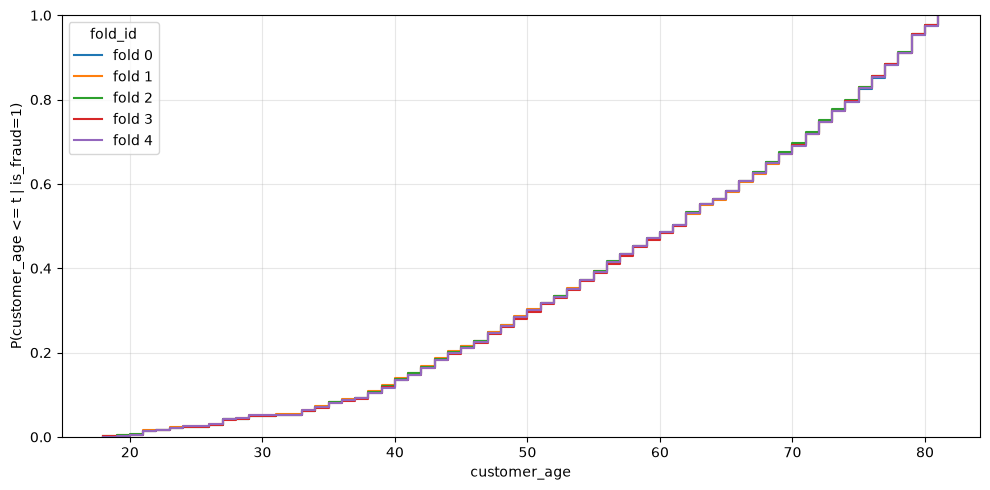

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\fraud_ecdf_fold_stability\plots\fold_curves\merchant_risk_score_fraud_ecdf_by_fold.png


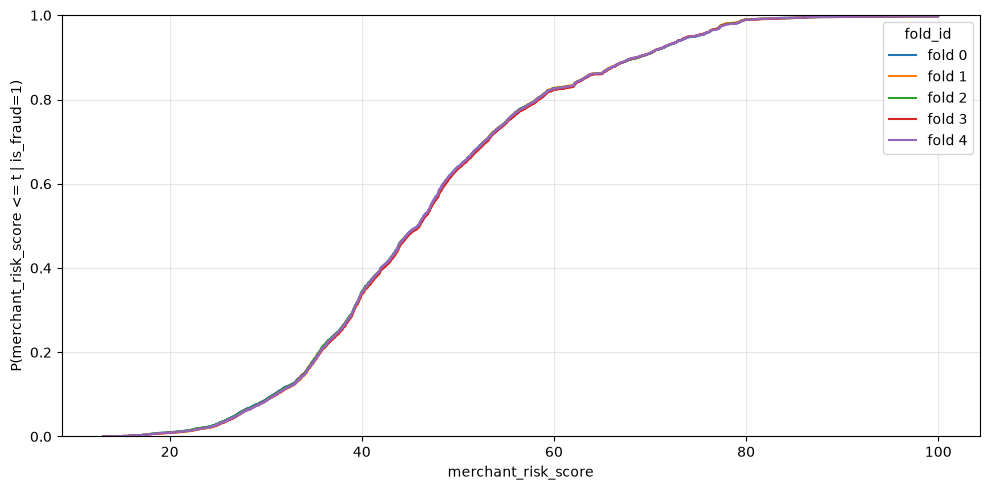

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\fraud_ecdf_fold_stability\plots\fold_curves\velocity_score_fraud_ecdf_by_fold.png


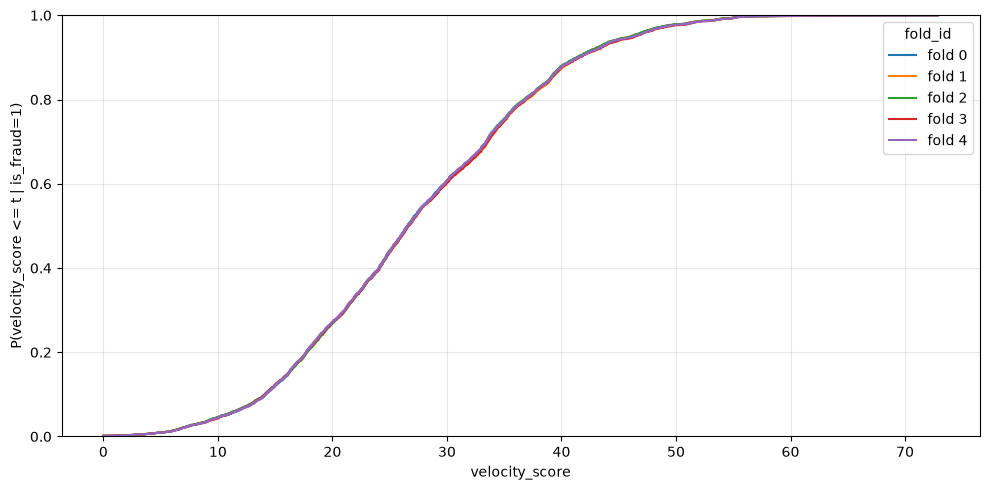

In [3]:
CURVE_SECTION = "fold_curves"

for col_i in range(n_columns):
    name = FRAUD_ECDF_COLUMNS[col_i]
    parts: list[pd.DataFrame | None] = [None] * n_folds
    for fold_id in range(n_folds):
        curve = fold_curves[col_i][fold_id]
        if curve is None:
            raise ValueError(f"missing curve for {name} fold {fold_id}")
        table = curve.curve_table()
        table["fold_id"] = fold_id
        parts[fold_id] = table
    overlay = pd.concat([part for part in parts if part is not None], ignore_index=True)
    fig, ax = categorical_numeric.plot_conditional_cdf(
        overlay,
        x=name,
        cdf="cdf",
        group="fold_id",
        x_scale="linear",
        group_labels=FOLD_LABELS,
    )
    ax.set_ylabel(f"P({name} <= t | {TARGET_COLUMN}=1)")
    plot_path = (
        get_script_plot_dir(NOTEBOOK_STEM, section=CURVE_SECTION)
        / f"{name}_fraud_ecdf_by_fold.png"
    )
    fig.savefig(plot_path, dpi=140)
    print("saved", plot_path)
    plt.show()


## How far apart are the folds?

`max_t |F_i(t) - F_j(t)|` on the union of jump points (enough for two step ECDFs). Also each fold versus the full-train curve.

In [4]:
n_pairs = n_folds * (n_folds - 1) // 2
n_pair_rows = n_columns * n_pairs
pair_rows: list[dict[str, object] | None] = [None] * n_pair_rows
n_vs_full_rows = n_columns * n_folds
vs_full_rows: list[dict[str, object] | None] = [None] * n_vs_full_rows
pair_i = 0
vs_i = 0
for col_i in range(n_columns):
    name = FRAUD_ECDF_COLUMNS[col_i]
    filled_folds = [curve for curve in fold_curves[col_i] if curve is not None]
    if len(filled_folds) != n_folds:
        raise ValueError(f"missing a fold curve for {name}")
    curves = tuple(filled_folds)
    full = full_curves[col_i]
    if full is None:
        raise ValueError(f"missing full-train curve for {name}")
    grid = common_grid(curves + (full,))
    for fold_a in range(n_folds):
        vs_full_rows[vs_i] = {
            "column": name,
            "fold_id": fold_a,
            "max_abs_diff_vs_full": max_abs_difference(
                curves[fold_a],
                full,
                grid=grid,
            ),
        }
        vs_i += 1
        for fold_b in range(fold_a + 1, n_folds):
            pair_rows[pair_i] = {
                "column": name,
                "fold_a": fold_a,
                "fold_b": fold_b,
                "max_abs_diff": max_abs_difference(
                    curves[fold_a],
                    curves[fold_b],
                    grid=grid,
                ),
            }
            pair_i += 1

pairwise = pd.DataFrame([row for row in pair_rows if row is not None])
vs_full = pd.DataFrame([row for row in vs_full_rows if row is not None])
summary = (
    pairwise.groupby("column", sort=False)["max_abs_diff"]
    .agg(max_pairwise="max", mean_pairwise="mean")
    .join(
        vs_full.groupby("column", sort=False)["max_abs_diff_vs_full"].agg(
            max_vs_full="max",
            mean_vs_full="mean",
        )
    )
    .reindex(list(FRAUD_ECDF_COLUMNS))
)
print(summary.round(6))
print(DELIMITER_VALUE)
print(pairwise.round(6))
pair_path = tables_dir / "fold_pairwise_max_abs_diff.csv"
vs_path = tables_dir / "fold_vs_full_max_abs_diff.csv"
summary_path = tables_dir / "fold_stability_summary.csv"
pairwise.to_csv(pair_path, index=False)
vs_full.to_csv(vs_path, index=False)
summary.to_csv(summary_path)
print("saved", pair_path)
print("saved", vs_path)
print("saved", summary_path)


                     max_pairwise  mean_pairwise  max_vs_full  mean_vs_full
column                                                                     
customer_age             0.007058       0.005375     0.004314      0.003346
merchant_risk_score      0.008021       0.006250     0.004778      0.003916
velocity_score           0.007700       0.005808     0.004165      0.003754
--------------------------------------------------
                 column  fold_a  fold_b  max_abs_diff
0          customer_age       0       1      0.003885
1          customer_age       0       2      0.004366
2          customer_age       0       3      0.005427
3          customer_age       0       4      0.003716
4          customer_age       1       2      0.006096
5          customer_age       1       3      0.006203
6          customer_age       1       4      0.005775
7          customer_age       2       3      0.007058
8          customer_age       2       4      0.006630
9          customer_age      